## Environments & Imports

In [6]:
import os
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

# Set plotting style
sns.set_theme(style="darkgrid")
plt.rcParams["figure.dpi"] = 150

## Resolve Dataset Path via kagglehub

In [7]:
# Download/locate dataset via kagglehub
dataset_path = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
print(f"Dataset root: {dataset_path}")

# Inspect top-level directories
subdirs = [p.name for p in dataset_path.iterdir() if p.is_dir()]
print(f"Subdirectories: {subdirs}")

100%|██████████| 157M/157M [00:40<00:00, 4.06MB/s] 

Extracting files...


Dataset root: /Users/ronitsaxena/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2
Subdirectories: ['Training', 'Testing']


## Class Distribution Analysis

      Split       Class  Count
0  Training   pituitary   1400
1  Training     notumor   1400
2  Training      glioma   1400
3  Training  meningioma   1400
4   Testing   pituitary    400
5   Testing     notumor    400
6   Testing      glioma    400
7   Testing  meningioma    400


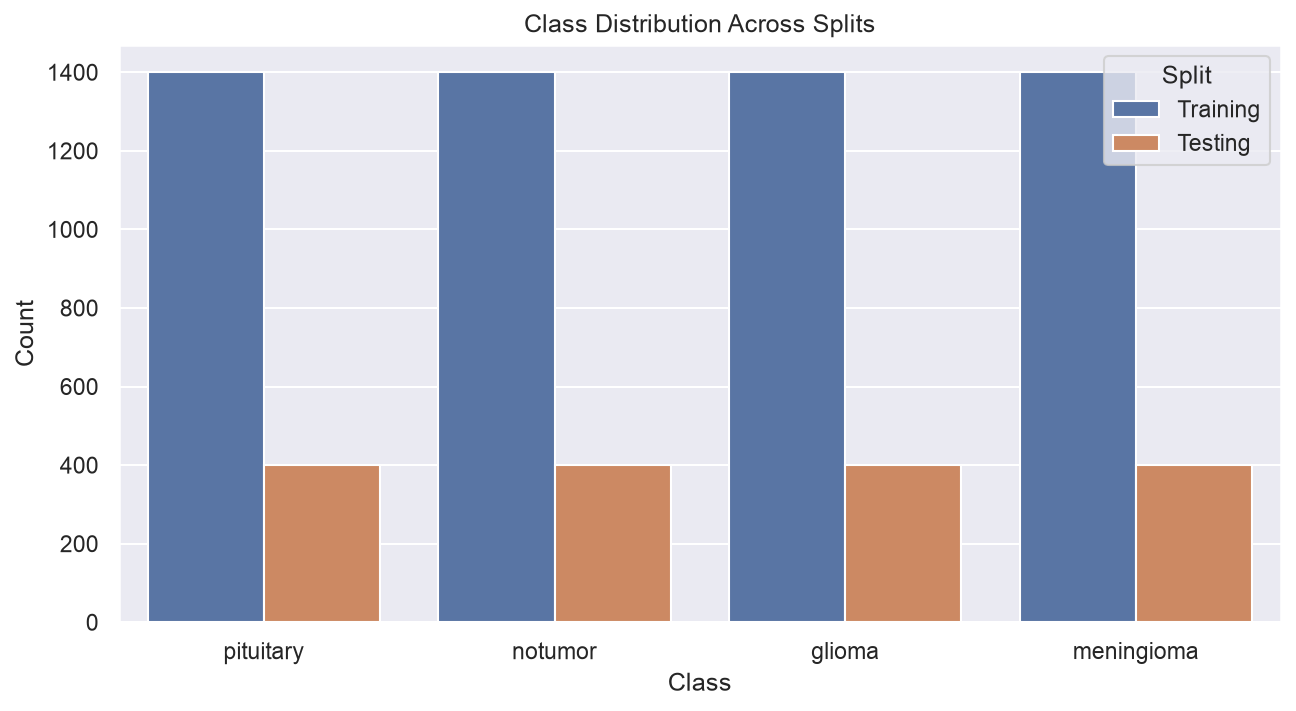

In [8]:
def get_class_counts(split_path: Path):
    counts = {}
    if split_path.exists():
        for class_dir in split_path.iterdir():
            if class_dir.is_dir():
                counts[class_dir.name] = len(list(class_dir.glob("*.[jJ][pP][gG]")) + list(class_dir.glob("*.[pP][nN][gG]")))
    return counts

splits = ["Training", "Testing"]
distribution_data = []

for split in splits:
    split_dir = dataset_path / split
    counts = get_class_counts(split_dir)
    for cls, count in counts.items():
        distribution_data.append({"Split": split, "Class": cls, "Count": count})

df_dist = pd.DataFrame(distribution_data)
print(df_dist)

# Plot distribution
plt.figure(figsize=(10, 5))
sns.barplot(data=df_dist, x="Class", y="Count", hue="Split")
plt.title("Class Distribution Across Splits")
plt.show()

## Image Dimensions & Channel Audit
Checking variance in image resolutions is critical for deciding whether to pad or distort during preprocessing.

In [9]:
image_stats = []

for split in splits:
    split_dir = dataset_path / split
    if not split_dir.exists():
        continue
    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue
        for img_path in list(class_dir.glob("*.[jJ][pP][gG]"))[:100]: # Sample 100 per class for speed
            with Image.open(img_path) as img:
                image_stats.append({
                    "Split": split,
                    "Class": class_dir.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode
                })

df_stats = pd.DataFrame(image_stats)
print("Image modes found:", df_stats["Mode"].unique())
print("Dimension summary:\n", df_stats[["Width", "Height"]].describe())

Image modes found: <StringArray>
['L', 'RGB']
Length: 2, dtype: str
Dimension summary:
              Width       Height
count   800.000000   800.000000
mean    450.562500   453.607500
std     125.939279   123.562831
min     150.000000   167.000000
25%     441.000000   442.000000
50%     512.000000   512.000000
75%     512.000000   512.000000
max    1338.000000  1304.000000


## Visualizing Sample Images (Grid per Class)

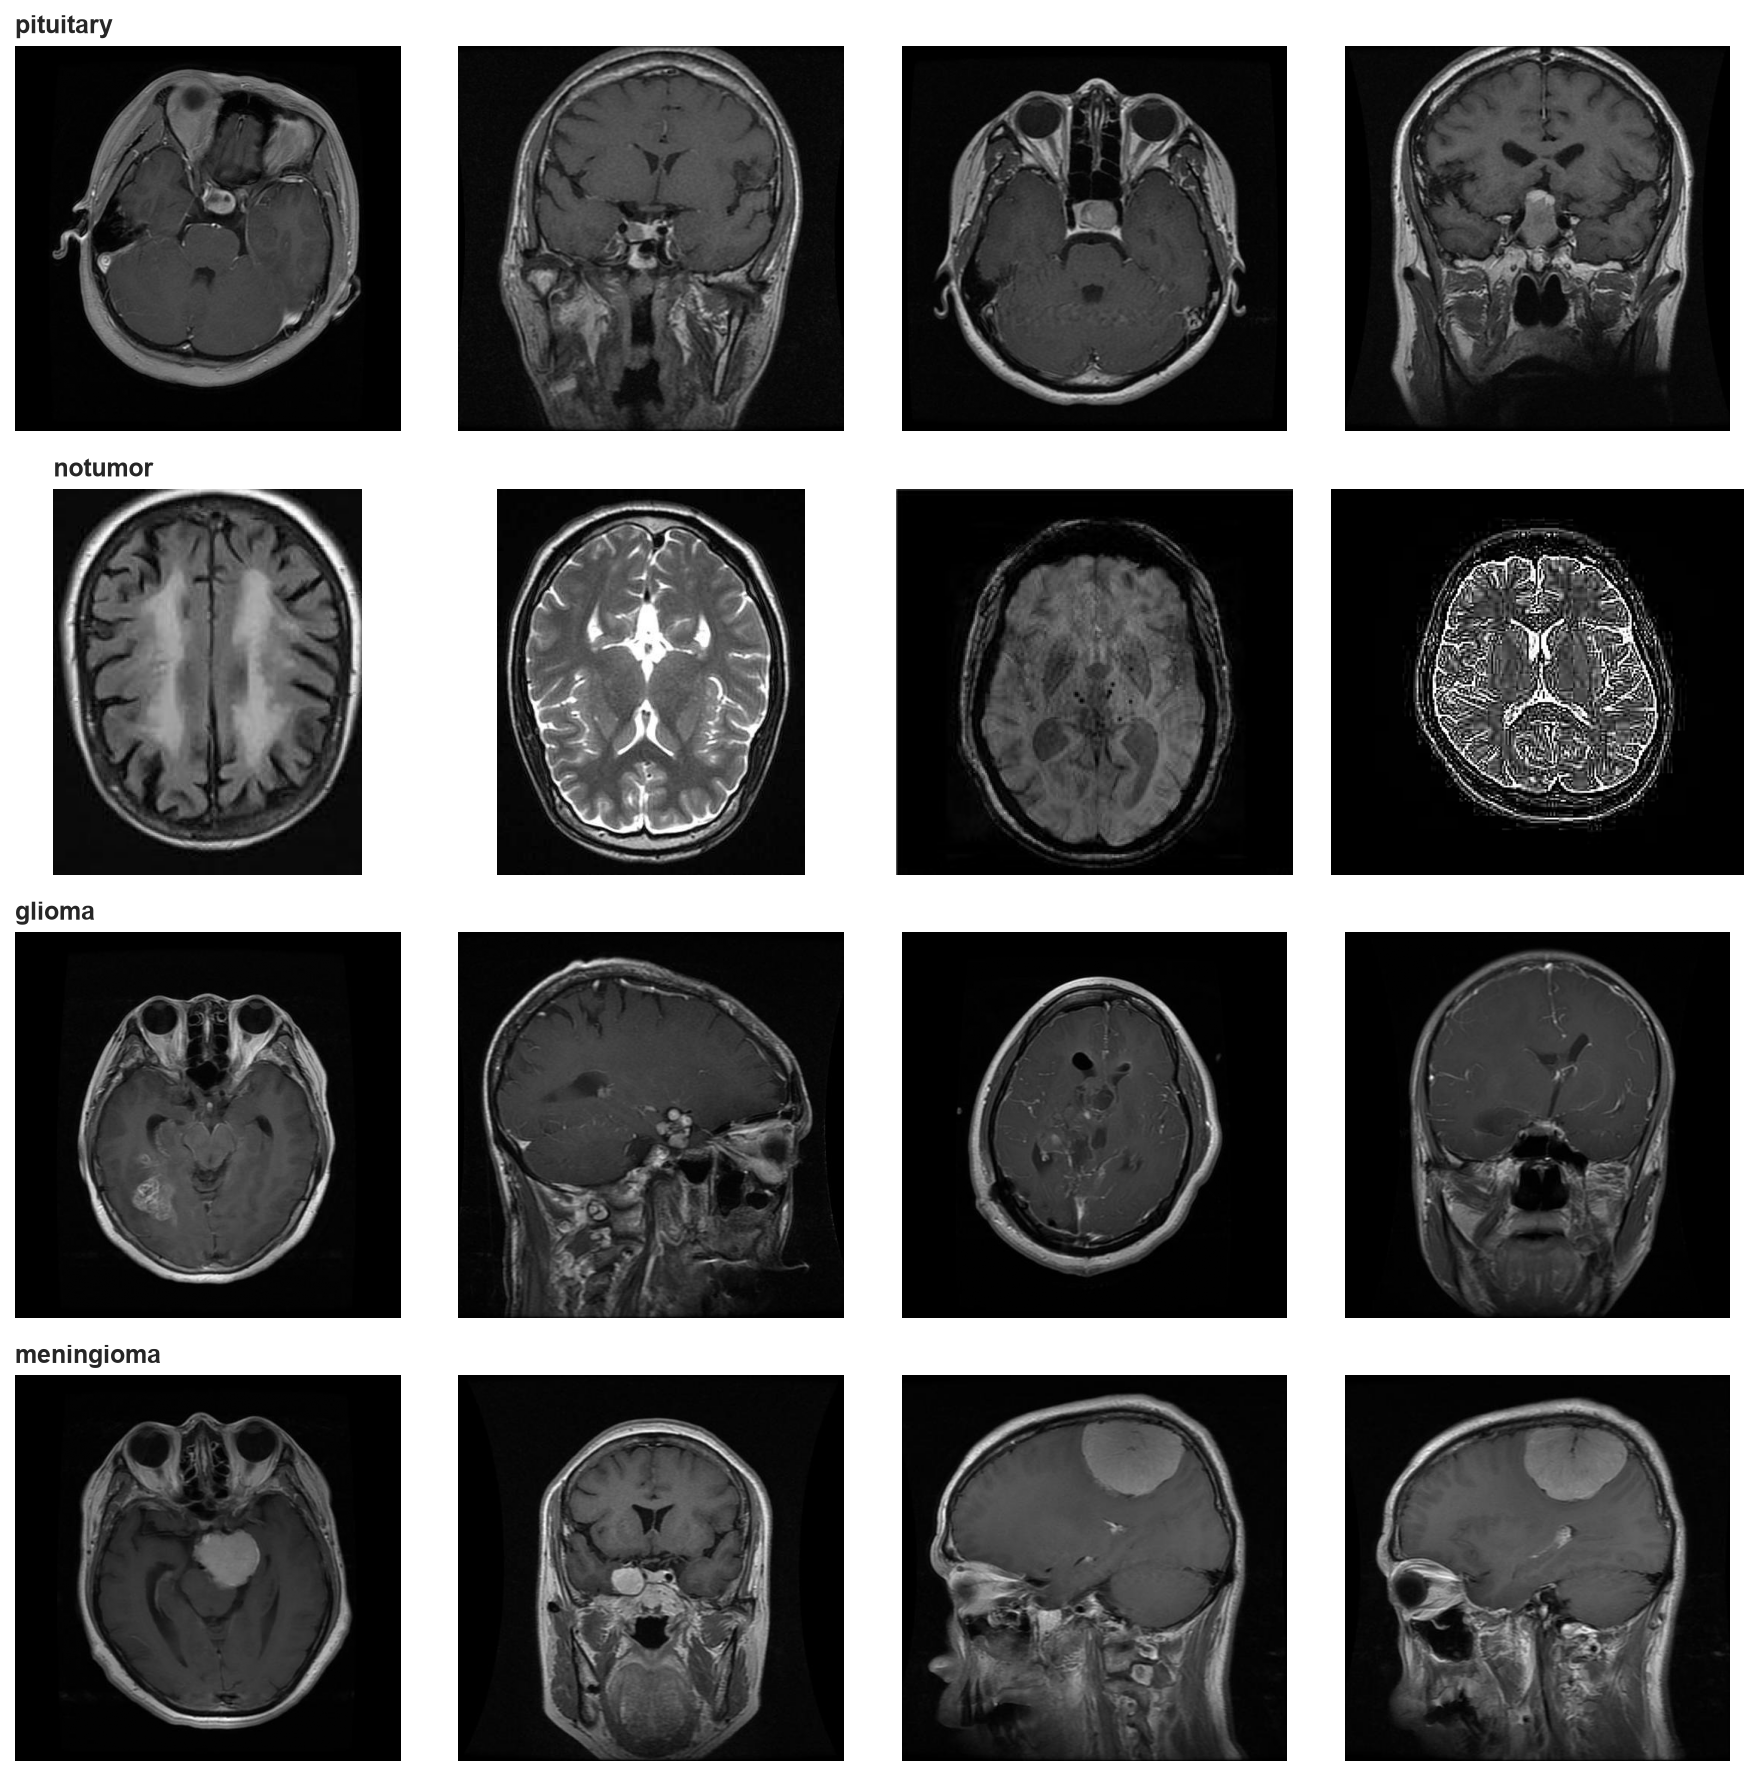

In [ ]:
classes = [d.name for d in (dataset_path / "Training").iterdir() if d.is_dir()]

fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))

for i, cls in enumerate(classes):
    cls_dir = dataset_path / "Training" / cls
    sample_images = list(cls_dir.glob("*.[jJ][pP][gG]"))[:4]

    for j, img_path in enumerate(sample_images):
        ax = axes[i, j] if len(classes) > 1 else axes[j]
        img = Image.open(img_path)
        ax.imshow(img, cmap="gray" if img.mode == "L" else None)
        ax.axis("off")
        if j == 0:
            ax.set_title(cls, fontsize=12, fontweight="bold", loc="left")

plt.tight_layout()
plt.show()

## Summary

This notebook profiles the [Brain Tumor MRI dataset](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset) (`masoudnickparvar/brain-tumor-mri-dataset`) as a baseline for the MRI vision benchmark.

**Dataset layout.** KaggleHub resolves the archive into two splits, `Training` and `Testing`, with four classes in each: `glioma`, `meningioma`, `pituitary`, and `notumor`.

**Class balance.** The splits are perfectly balanced. Each class has **1,400** training images and **400** test images (**5,600** train / **1,600** test, **7,200** total). Accuracy metrics later in the harness will not need class weighting to correct for imbalance.

**Image properties.** A sample of 100 images per class per split (800 images) shows mixed color modes (`L` and `RGB`) and a wide resolution range. The median size is **512×512**, but widths run from **150** to **1,338** and heights from **167** to **1,304** (mean about **451×454**). Preprocessing should resize to a fixed input and normalize channel count before model comparison.

**Visual check.** A 4-image grid per training class shows representative slices from each label, including both grayscale and color images.